# Does Game Script Hide the Link Between Rushing and Winning?

**Follow-up to 01_team_rushing_efficiency.ipynb.** In the first analysis, passing efficiency was far more closely tied to win percentage than rushing efficiency (2022-2025). One limitation was *game script*: teams that lead run more to burn the clock, and teams that trail pass more, so rushing and passing numbers partly reflect the score, not just skill.

**Question:** If we keep only plays from competitive, "neutral" game situations, does the relationship between rushing efficiency and winning change?

In [1]:
import os
import nflreadpy as nfl
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

seasons = [2022, 2023, 2024, 2025]
pbp = nfl.load_pbp(seasons).to_pandas()

reg = pbp[(pbp["season_type"] == "REG") & pbp["posteam"].notna() & pbp["epa"].notna()].copy()
print(reg.shape)

(176902, 372)


## 1. Define "neutral" game situations

A play counts as neutral if the offense's win probability is between 20% and 80%, more than two minutes remain in the half, and it is not overtime. This removes garbage time, end-of-half clock management, and plays where the outcome is nearly decided. It keeps **56% of all plays**. These cutoffs are judgment calls, so Section 4 tests alternatives.

In [2]:
neutral = reg[
    reg["wp"].between(0.2, 0.8) &
    (reg["half_seconds_remaining"] > 120) &
    (reg["qtr"] <= 4)
].copy()

print("All plays:    ", len(reg))
print("Neutral plays:", len(neutral))
print("Share kept:   ", round(len(neutral) / len(reg), 2))

All plays:     176902
Neutral plays: 98208
Share kept:    0.56


## 2. Build team-season tables

For each team in each season I calculate EPA per rush, EPA per pass, and win percentage (ties count as half a win), once with all plays and once with neutral plays only. Each version has 128 team-seasons (32 teams x 4 seasons). In the neutral version, the smallest team-season still has 162 rushes and 227 passes, which is enough for stable averages.

In [3]:
def team_epa(df, label):
    rush = (df[(df["rush_attempt"] == 1) & (df["qb_scramble"] == 0)]
            .groupby(["season", "posteam"])
            .agg(epa_per_rush=("epa", "mean"), rushes=("epa", "size"))
            .reset_index())
    pas = (df[df["pass"] == 1]
           .groupby(["season", "posteam"])
           .agg(epa_per_pass=("epa", "mean"), passes=("epa", "size"))
           .reset_index())
    out = rush.merge(pas, on=["season", "posteam"])
    out["version"] = label
    return out

sched = nfl.load_schedules(seasons).to_pandas()
sched = sched[(sched["game_type"] == "REG") & sched["result"].notna()]
home = sched[["season", "home_team", "home_score", "away_score"]].set_axis(["season", "team", "pf", "pa"], axis=1)
away = sched[["season", "away_team", "away_score", "home_score"]].set_axis(["season", "team", "pf", "pa"], axis=1)
games = pd.concat([home, away])
games["win"] = (games["pf"] > games["pa"]).astype(float)
games.loc[games["pf"] == games["pa"], "win"] = 0.5
rec = games.groupby(["season", "team"]).agg(win_pct=("win", "mean")).reset_index()

all_df = team_epa(reg, "All plays").merge(rec, left_on=["season", "posteam"], right_on=["season", "team"])
neu_df = team_epa(neutral, "Neutral situations").merge(rec, left_on=["season", "posteam"], right_on=["season", "team"])

print(len(all_df), len(neu_df))
print(neu_df[["rushes", "passes"]].describe().round(0))

128 128
       rushes  passes
count   128.0   128.0
mean    248.0   359.0
std      33.0    46.0
min     162.0   227.0
25%     226.0   331.0
50%     248.0   360.0
75%     264.0   382.0
max     329.0   475.0


In [4]:
for df in [all_df, neu_df]:
    print(df["version"].iloc[0])
    print("  rush vs win%:", round(df["epa_per_rush"].corr(df["win_pct"]), 3))
    print("  pass vs win%:", round(df["epa_per_pass"].corr(df["win_pct"]), 3))

All plays
  rush vs win%: 0.345
  pass vs win%: 0.721
Neutral situations
  rush vs win%: 0.479
  pass vs win%: 0.641


## 3. Results: correlations with win percentage

| | All plays | Neutral situations |
|---|---|---|
| Rushing EPA vs. win % | r = 0.35 (about 12% of variance) | r = 0.48 (about 23%) |
| Passing EPA vs. win % | r = 0.72 (about 52%) | r = 0.64 (about 41%) |

**Interpretation:** Restricting to neutral situations *strengthened* rushing's link to winning and *weakened* passing's. That is consistent with game script affecting both: lopsided games add noise to rushing numbers and boost the apparent value of passing. Passing efficiency is still the stronger predictor, but the gap narrowed substantially (a difference of about 0.38 in correlation became about 0.16).

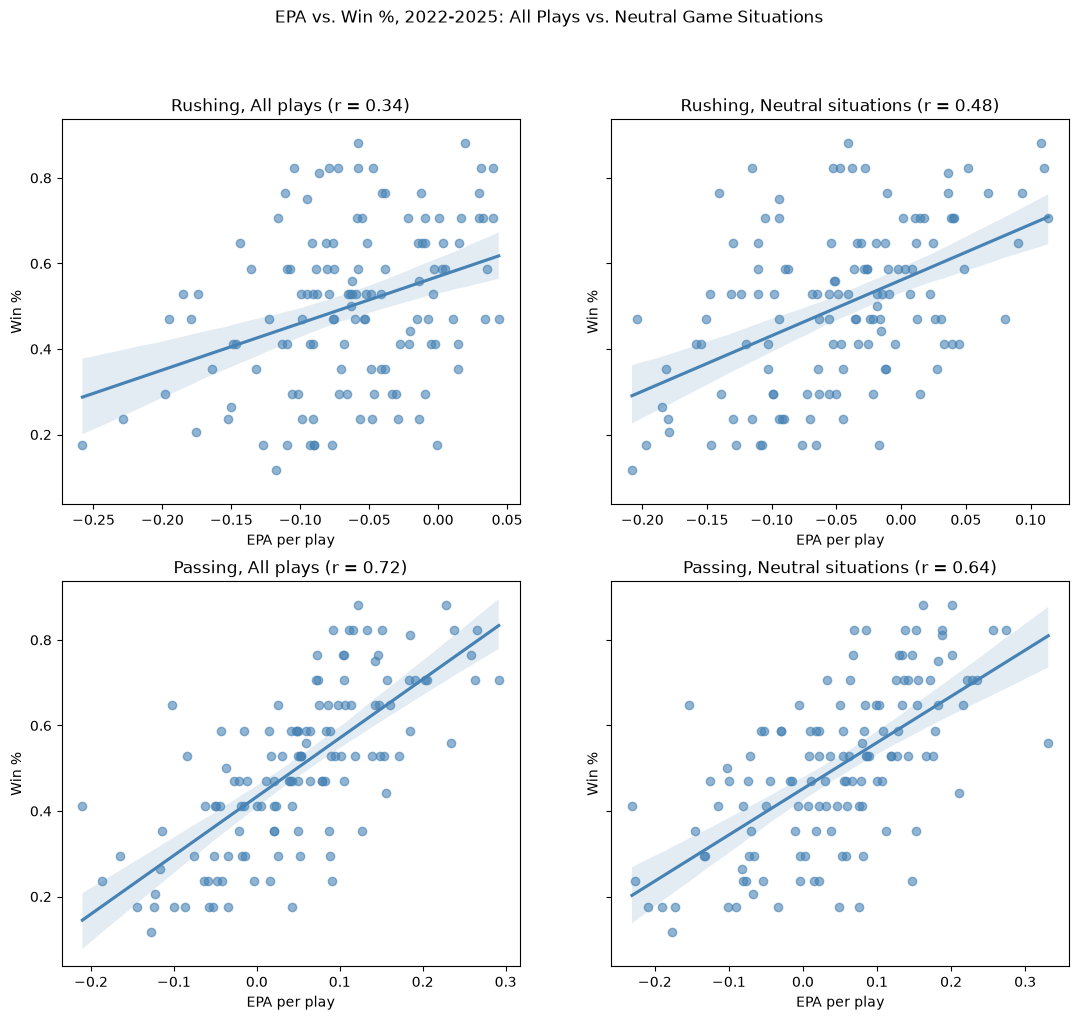

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 11), sharey=True)
for row, (col, name) in enumerate([("epa_per_rush", "Rushing"), ("epa_per_pass", "Passing")]):
    for c, df in enumerate([all_df, neu_df]):
        ax = axes[row][c]
        sns.regplot(data=df, x=col, y="win_pct", color="steelblue", ax=ax, scatter_kws={"alpha": 0.6})
        r = df[col].corr(df["win_pct"])
        ax.set_title(f"{name}, {df['version'].iloc[0]} (r = {r:.2f})")
        ax.set_xlabel("EPA per play")
        ax.set_ylabel("Win %")

fig.suptitle("EPA vs. Win %, 2022-2025: All Plays vs. Neutral Game Situations")
os.makedirs("images", exist_ok=True)
plt.savefig("images/neutral_vs_all_plays.png", dpi=200, bbox_inches="tight")
plt.show()

**Reading the chart:** The top row is rushing and the bottom row is passing. The left column uses all plays and the right column uses neutral plays only. The rushing trend line gets noticeably steeper and the points cluster closer to it in the neutral version, while the passing line is slightly flatter. Passing still shows the tighter band overall.

In [6]:
for lo, hi in [(0.1, 0.9), (0.2, 0.8), (0.3, 0.7)]:
    sub = reg[reg["wp"].between(lo, hi) & (reg["half_seconds_remaining"] > 120) & (reg["qtr"] <= 4)]
    d = team_epa(sub, "x").merge(rec, left_on=["season", "posteam"], right_on=["season", "team"])
    print(f"wp {lo}-{hi}: rush r = {d['epa_per_rush'].corr(d['win_pct']):.3f}, pass r = {d['epa_per_pass'].corr(d['win_pct']):.3f}")

wp 0.1-0.9: rush r = 0.486, pass r = 0.671
wp 0.2-0.8: rush r = 0.479, pass r = 0.641
wp 0.3-0.7: rush r = 0.473, pass r = 0.582


## 4. Robustness check: does the answer depend on my cutoffs?

I repeated the analysis with wider (10-90%) and narrower (30-70%) win-probability windows.

**Interpretation:** Rushing's correlation barely changed across definitions (r = 0.473 to 0.486), so that result is not sensitive to the exact cutoff. Passing's correlation fell steadily as the window tightened (0.671, 0.641, 0.582), which suggests part of passing's association with winning comes from plays in lopsided games.

## 5. Conclusions and limitations

**Conclusion:** After controlling for game situation, rushing efficiency is more strongly associated with winning than the first analysis suggested (r = 0.48 vs. 0.35), but passing efficiency remains the stronger predictor (r = 0.64).

**Limitations**
- These are correlations on 128 team-seasons, not causal estimates, and the differences between correlations were not tested for statistical significance.
- Team-seasons from the same franchise are not fully independent.
- Win probability is itself a model output. If it incorporates pre-game team strength, filtering on it may remove more plays from the strongest and weakest teams. I did not examine that here.
- Defense, special teams, turnovers and injuries are not modeled.

**Next steps:** split rushing by run direction and gap, and build a play-level model of rushing success.